# pluvigeo: exemplo de uso

A biblioteca faz três coisas com dados do Cemaden: **diagnóstico de integridade** da chuva e da umidade
do solo, **ajuste da resolução temporal** (10 min → 1 h → 1 dia → mês) e **plotagem** (matplotlib, e
versões interativas em plotly com o sufixo `_interativo`). Os dados podem vir do **PED** (um arquivo por
estação) ou do **mapa interativo** (um arquivo por mês); a leitura entrega a mesma tabela nos dois casos.

A pluvigeo é uma biblioteca do GRAPHID (Projeto SALAD), independente do Cemaden. Nenhuma célula altera
os arquivos originais; o que é gravado vai para a pasta `saida_exemplo/`. As regras, os valores padrão e
as referências estão em `docs/regras.md`; as entradas e saídas de cada função, em `docs/funcoes.md`.

## A ordem do processamento

| Etapa | Função | Recebe | Devolve |
|---|---|---|---|
| 1. Ler | `leitura.ler_dados` | arquivos CSV | `dados`, `estacoes` |
| | `leitura.inventario_dados` | `dados` | o que tem em cada estação |
| 2. Chuva | `leitura.chuva_por_estacao` | `dados` | `pluv_raw` |
| | `chuva.regularizar_chuva` | `pluv_raw` | `pluv_reg` |
| | `chuva.relatorio_falhas`, `retornos_pos_falha`, `acumulados`, `resumo_estacao` | `pluv_reg` | tabelas de diagnóstico |
| 3. Umidade | `leitura.umidade_por_estacao` + `figuras.serie_umidade_interativo` | `dados` | `umid_raw`, para escolher a acomodação |
| | `umidade.limpar_umidade` | `dados` + código + acomodação | `umid_clean` |
| | `umid_clean[cod].mascaras` | `umid_clean[cod]` | onde cada regra marcou |
| 4. Exclusão manual | `exclusao.excluir_periodos` | `pluv_reg[cod]` ou `umid_clean[cod]` | o mesmo objeto, com a exclusão |
| 5. Resolução | `resolucao.reamostrar_chuva`, `reamostrar_umidade` | `pluv_reg[cod]`, `umid_clean[cod].operacional` | `pluv_rs`, `umid_rs` |
| 6. Figuras e exportação | `figuras.*`, `to_csv` | qualquer etapa | figuras e arquivos |

## Os nomes dos objetos

O prefixo diz a variável (`pluv` = chuva, `umid` = umidade) e o sufixo diz a etapa: `raw` (como foi
lido), `reg` (chuva em resolução temporal regular, com as falhas marcadas), `clean` (umidade limpa) e `rs`
(*resample*, reamostrado). Cada objeto é um **dicionário** `{código da estação: dado}`:
`pluv_reg['330390605G']` é a chuva de uma estação. As estações são sempre identificadas pelo código
completo, que não se repete entre municípios e estados.

## Os parâmetros

A primeira vez que cada função aparece, a chamada traz **todos os parâmetros**, com os valores padrão e
um comentário dizendo o que cada um faz; nas chamadas seguintes, só o que muda. Assim dá para ver as
possibilidades sem abrir a documentação (os detalhes estão em `docs/funcoes.md`).

## Os dados deste exemplo

O notebook roda com um **recorte de dados reais** do Cemaden, de estações de Petrópolis (RJ), que fica
em `exemplos/dados/`: as linhas foram copiadas dos arquivos originais sem alteração, só nos períodos
usados aqui, e compactadas (`.csv.gz`). Os dados são do Cemaden; a descrição e o crédito estão em
`exemplos/dados/LEIAME.md`. Para usar os seus dados, baixe-os do PED (https://ped.cemaden.gov.br) ou
do mapa interativo (https://mapainterativo.cemaden.gov.br) e troque o caminho em `DADOS`.

## 0. Preparação

Instale a biblioteca uma vez, no ambiente do Anaconda que este notebook usa (no terminal, dentro da
pasta `pluvigeo`): `pip install -e ".[notebook]"` (o `[notebook]` instala também o ipykernel). Com ela
instalada, o editor mostra a descrição e os parâmetros de cada função; em qualquer caso,
`help(chuva.regularizar_chuva)` ou `chuva.regularizar_chuva?` mostram o mesmo.

Para usar os seus arquivos, troque o caminho em `DADOS`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import plotly.io as pio

RAIZ = Path.cwd().parent
try:
    import pluvigeo                                  # biblioteca instalada (recomendado; ver README)
except ImportError:
    sys.path.insert(0, str(RAIZ / 'src'))            # não instalada: usa direto da pasta src/

from pluvigeo import leitura, chuva, umidade, exclusao, resolucao, figuras

# Onde estão os dados: o recorte real que acompanha o exemplo (troque pelo seu caminho)
DADOS = Path('dados')

SAIDA = Path('saida_exemplo')          # tudo o que este notebook grava vai para cá
SAIDA.mkdir(exist_ok=True)
pd.set_option('display.width', 200)

# Figuras interativas: carregam o plotly pela internet, o que deixa o arquivo do notebook leve
# (exige o nbformat, instalado com: pip install -e ".[notebook]")
pio.renderers.default = 'plotly_mimetype+notebook_connected'

## 1. Leitura

### `leitura.ler_dados`

Lê um arquivo, uma pasta ou uma lista, de qualquer dos dois formatos (o formato de cada arquivo é
reconhecido pelo cabeçalho), converte o horário de UTC para o de Brasília e remove as linhas repetidas.

- **Entrada:** `caminho` (arquivo, pasta ou lista).
- **Parâmetros:** `fuso=-3` (horas somadas ao UTC); `sensores=None` (lista de ids a manter, ex.: `[10]`
  para só chuva; para limpar a umidade, leia sem filtrar).
- **Saída:** `dados` (tabela padronizada: uma linha por estação, instante e sensor), `estacoes` (nome,
  município, UF, coordenadas) e `n_dup` (linhas repetidas removidas).

In [2]:
# Um arquivo do PED (todos os sensores de uma PCD Geo: chuva e umidade)
dados_geo, estacoes_geo, n_dup = leitura.ler_dados(
    DADOS / 'PED_Cemaden_330390605G.csv.gz',   # um arquivo, uma pasta ou uma lista deles
    fuso=-3,                                    # horas a somar ao horário do arquivo (UTC); -3 = Brasília
    sensores=None,                              # lista de id_sensor a manter (ex.: [10] = só chuva); None = todos
    padrao='*.csv*',                            # numa pasta, quais arquivos ler (CSV e CSV compactado)
)
print(f'{len(dados_geo):,} linhas; {n_dup} duplicatas removidas')
display(estacoes_geo)
dados_geo.head()

222,733 linhas; 768 duplicatas removidas


,codestacao,nome,municipio,uf,latitude,longitude
0,330390605G,Bingen - Geo,PETRÓPOLIS,RJ,-22.51221,-43.209475


,codestacao,nome,datahora,id_sensor,valor,qualificacao
0,330390605G,Bingen - Geo,2021-11-22 16:10:00,10,3.8,4
1,330390605G,Bingen - Geo,2021-11-22 16:20:00,10,16.8,4
2,330390605G,Bingen - Geo,2021-11-22 16:30:00,10,0.2,4
3,330390605G,Bingen - Geo,2021-11-22 17:10:00,10,0.0,0
4,330390605G,Bingen - Geo,2021-11-22 18:10:00,10,0.0,0


O mapa interativo entra pela mesma função e sai com as mesmas colunas.

In [3]:
# Um arquivo mensal do mapa interativo (fevereiro de 2022: todas as estações do município, só chuva)
dados_mapa, estacoes_mapa, n_dup = leitura.ler_dados(DADOS / 'mapa_interativo')
print(f'{len(dados_mapa):,} linhas, {len(estacoes_mapa)} estações')
dados_mapa.head()

19,763 linhas, 21 estações


,codestacao,nome,datahora,id_sensor,valor,qualificacao
0,330390601G,Quitandinha - Geo,2022-01-31 21:10:00,10,0.0,NaN
1,330390601G,Quitandinha - Geo,2022-01-31 22:10:00,10,0.0,NaN
2,330390601G,Quitandinha - Geo,2022-01-31 23:10:00,10,0.0,NaN
3,330390601G,Quitandinha - Geo,2022-02-01 00:10:00,10,0.0,NaN
4,330390601G,Quitandinha - Geo,2022-02-01 01:10:00,10,0.0,NaN


#### Fuso horário

Os arquivos do Cemaden vêm em **UTC**. Por padrão a leitura converte para o horário de Brasília
(`fuso=-3`, fixo, sem horário de verão). Para manter o UTC original, use `fuso=0`.

In [4]:
arq = DADOS / 'PED_Cemaden_330390605G.csv.gz'
utc = leitura.ler_dados(arq, fuso=0, sensores=[10]).dados
local = leitura.ler_dados(arq, sensores=[10]).dados          # padrão: -3
pd.DataFrame({'UTC (como no arquivo)': utc.datahora.head(3), 'Brasília (padrão)': local.datahora.head(3)})

,UTC (como no arquivo),Brasília (padrão)
0,2021-11-22 19:10:00,2021-11-22 16:10:00
1,2021-11-22 19:20:00,2021-11-22 16:20:00
2,2021-11-22 19:30:00,2021-11-22 16:30:00


### `leitura.inventario_dados`

Confere o que foi lido: uma linha por estação, com o período, o número de linhas, os sensores presentes
e os **ids desconhecidos** (fora do dicionário da biblioteca; um id novo pode indicar mudança no formato
do Cemaden).

- **Entrada:** `dados`. **Parâmetro:** `estacoes` (opcional), que acrescenta município, UF e coordenadas.
- **Saída:** uma tabela, uma linha por estação.

In [5]:
leitura.inventario_dados(dados_mapa,
                         estacoes=estacoes_mapa)    # opcional: acrescenta município, UF e coordenadas
# reparar que os dados baixados do mapa interativos foram apenas referentes à precipitação, até para as estacoes geotecnicas.

,codestacao,tipo,inicio,fim,linhas,tem_umidade,sensores,ids_desconhecidos,municipio,uf,latitude,longitude
0,330390601G,PCD Geo,2022-01-31 21:10:00,2022-02-27 20:10:00,1041,False,[10],[],PETRÓPOLIS,RJ,-22.524907,-43.223916
1,330390603G,PCD Geo,2022-02-01 01:40:00,2022-02-27 20:10:00,742,False,[10],[],PETRÓPOLIS,RJ,-22.528328,-43.202885
2,330390604G,PCD Geo,2022-01-31 21:10:00,2022-02-27 20:10:00,1021,False,[10],[],PETRÓPOLIS,RJ,-22.536909,-43.193240
3,330390605A,pluviômetro,2022-01-31 21:20:00,2022-02-27 20:20:00,666,False,[10],[],PETRÓPOLIS,RJ,-22.427000,-43.249000
4,330390605G,PCD Geo,2022-01-31 21:10:00,2022-02-27 20:10:00,1060,False,[10],[],PETRÓPOLIS,RJ,-22.512210,-43.209475
5,330390606A,pluviômetro,2022-01-31 21:30:00,2022-02-27 20:30:00,1124,False,[10],[],PETRÓPOLIS,RJ,-22.374000,-43.046000
6,330390608A,pluviômetro,2022-01-31 21:50:00,2022-02-27 20:50:00,646,False,[10],[],PETRÓPOLIS,RJ,-22.428000,-43.058000
7,330390609A,pluviômetro,2022-01-31 21:00:00,2022-02-27 20:00:00,1084,False,[10],[],PETRÓPOLIS,RJ,-22.401000,-43.097000
8,330390611A,pluviômetro,2022-01-31 21:50:00,2022-02-27 20:50:00,958,False,[10],[],PETRÓPOLIS,RJ,-22.388000,-43.132000
9,330390612A,pluviômetro,2022-01-31 21:20:00,2022-02-27 20:20:00,998,False,[10],[],PETRÓPOLIS,RJ,-22.548000,-43.209000


## 2. Chuva: diagnóstico de integridade

### `leitura.chuva_por_estacao` e `chuva.regularizar_chuva`

`chuva_por_estacao` separa a chuva (sensor 10) de cada estação: devolve `pluv_raw`, um dicionário
`{código: série bruta}`. `regularizar_chuva` põe cada série numa **grade regular de 10 min** e marca as
falhas. Ela aceita o dicionário inteiro (e devolve outro dicionário, `pluv_reg`) ou uma estação só.

O pluviômetro transmite a cada 10 min quando chove e de hora em hora quando não chove. Um intervalo sem
registro pode ser "não choveu" ou "a estação não transmitiu". As regras:

| Situação | Tratamento | Parâmetro |
|---|---|---|
| até 5 intervalos vazios seguidos (o vazio normal entre duas transmissões horárias) | vale 0 mm | `max_intervalos_vazios=5` |
| mais do que isso | falha longa: fica NaN | |
| primeira leitura depois de uma falha longa, se for de 25 mm ou mais | marcada em `retorno_alto`; vira NaN (pode trazer a chuva acumulada do período fora do ar) | `limiar_retorno=25.0`, `excluir_retorno_alto=True` |
| 12 ou mais leituras transmitidas seguidas de 0,2 mm (regra empírica; ver o aviso abaixo) | vira NaN, marcada em `valor_repetido` | `filtrar_repetidos=True`, `min_repetidos=12`, `valor_repetido_mm=0.2` |
| leitura de 25 mm ou mais em 10 min | só marcada em `leitura_alta` | `limiar_leitura_alta=25.0` |

Na saída, `valor_original` guarda a leitura como veio e **`chuva_mm` é a série a usar**. Estas regras olham
uma estação por vez e só enxergam falhas de transmissão: um pluviômetro entupido, que transmite
normalmente e registra menos do que choveu, não é detectado.

In [6]:
# Chuva de todas as estações do PED na pasta (pluviômetros + PCDs Geo); sensor 10 = chuva
dados, estacoes, n_dup = leitura.ler_dados(DADOS, sensores=[10])
pluv_raw = leitura.chuva_por_estacao(dados, id_chuva=10)     # {código: série bruta}; 10 = sensor de chuva

# {código: tabela regular de 10 min}: aqui entram as regras de diagnóstico da chuva
pluv_reg = chuva.regularizar_chuva(
    pluv_raw,
    freq='10min',                 # passo da grade regular
    max_intervalos_vazios=5,      # até 5 intervalos vazios seguidos = não choveu (0 mm); mais = falha longa
    limiar_leitura_alta=25.0,     # mm num intervalo a partir do qual a leitura é marcada (só marca)
    limiar_retorno=25.0,          # mm; a 1ª leitura após uma falha longa, a partir daqui, é retorno alto
    excluir_retorno_alto=True,    # True = o retorno alto vira NaN; False = só fica marcado
    filtrar_repetidos=True,       # descarta o ruído de valor repetido (regra empírica; ver a seção do ruído)
    min_repetidos=12,             # nº de leituras transmitidas seguidas que caracteriza o ruído
    valor_repetido_mm=0.2,        # valor do ruído, em mm (None = qualquer valor não nulo)
)

pluv_reg['330390612A'].loc['2020-12-03 13:30':'2020-12-03 15:40']

,valor_original,ausente,grupo_falha,tamanho_bloco,falha_longa,retorno_pos_falha_longa,retorno_alto,valor_repetido,leitura_alta,exclusao_manual,valido,chuva_mm
datahora,,,,,,,,,,,,
2020-12-03 13:30:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN
2020-12-03 13:40:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN
2020-12-03 13:50:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN
2020-12-03 14:00:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN
2020-12-03 14:10:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN
2020-12-03 14:20:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN
2020-12-03 14:30:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN
2020-12-03 14:40:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN
2020-12-03 14:50:00,NaN,True,3928,74,True,False,False,False,False,False,False,NaN


### `chuva.relatorio_falhas`

Os números de falha de cada estação: período, % de funcionamento, falhas longas, retornos, leituras
repetidas e altas. Com o dicionário inteiro devolve uma tabela, uma linha por estação; com uma estação,
um dicionário. As colunas com `%` só se acessam entre colchetes: `relatorio['funcionamento_%']`.

In [7]:
relatorio = chuva.relatorio_falhas(pluv_reg)
relatorio.columns #Informações averiguadas

Index(['inicio', 'fim', 'total_dias', 'dias_com_falha_longa', 'dias_com_falha_%', 'n_falhas_longas', 'horas_em_falha', 'maior_falha_h', 'funcionamento_%', 'n_retornos_pos_falha',
       'n_retornos_descartados', 'n_leituras_repetidas', 'mm_repetidos_descartados', 'maior_retorno_mm', 'n_leituras_altas', 'maximo_valido_mm', 'data_maximo_valido'],
      dtype='str')

In [8]:
relatorio[['inicio', 'fim', 'funcionamento_%', 'n_falhas_longas', 'maior_falha_h', 'n_retornos_pos_falha',
           'n_retornos_descartados', 'maior_retorno_mm', 'n_leituras_altas', 'maximo_valido_mm']] #Reparar que este é um recorte. o Relatório em si é mais completo

,inicio,fim,funcionamento_%,n_falhas_longas,maior_falha_h,n_retornos_pos_falha,n_retornos_descartados,maior_retorno_mm,n_leituras_altas,maximo_valido_mm
330390602G,2021-11-22 09:30:00,2022-12-31 20:50:00,41.82,114,2126.0,114,3,48.6,4,33.0
330390605G,2021-11-22 16:10:00,2022-12-31 20:50:00,97.61,122,14.2,122,1,2.0,1,33.0
330390609A,2020-09-30 21:40:00,2020-12-31 20:40:00,77.67,169,9.2,169,22,0.2,0,0.58902
330390612A,2020-09-30 21:20:00,2020-12-31 20:30:00,73.34,115,42.0,115,84,3.544237,0,3.937733
330390618A,2016-12-31 21:00:00,2017-04-30 20:50:00,69.53,1,877.3,1,1,178.9594,1,21.229806


### `chuva.retornos_pos_falha`

As primeiras leituras depois de cada falha longa, da maior para a menor, com a duração da falha
anterior. Serve para ver se o retorno parece a chuva acumulada do período fora do ar. Os retornos
pequenos continuam valendo; os altos (`limiar_retorno`) são descartados. Para só marcá-los, use
`regularizar_chuva(..., excluir_retorno_alto=False)`.

In [9]:
chuva.retornos_pos_falha(pluv_reg['330390618A']).head(8)

,valor_original,duracao_falha_h,descartado
datahora,,,
2017-03-27 10:30:00,178.9594,877.33,True


In [10]:
# O mesmo retorno com excluir_retorno_alto=False: fica marcado em retorno_alto, mas continua valendo
so_marca = chuva.regularizar_chuva(pluv_raw['330390618A'], excluir_retorno_alto=False)
t = chuva.retornos_pos_falha(so_marca)
t

,valor_original,duracao_falha_h,descartado
datahora,,,
2017-03-27 10:30:00,178.9594,877.33,False


#### Ruído de 0,2 mm (valor repetido)

Em várias estações aparecem longos períodos em que toda leitura transmitida vale exatamente 0,2 mm
(uma basculada do pluviômetro). Hipótese: não é chuva, é ruído do equipamento ou água escoando aos poucos de um
funil parcialmente entupido. `regularizar_chuva` descarta as sequências de 12 ou mais leituras seguidas
de 0,2 mm e as marca em `valor_repetido`. O valor procurado é o parâmetro `valor_repetido_mm` (padrão 0,2;
`None` aceita qualquer valor não nulo). Para processar sem o filtro, use `filtrar_repetidos=False`.

> **Aviso: regra empírica.** O filtro de valor repetido foi desenvolvido de forma empírica, a partir da
> inspeção dos dados de Petrópolis (RJ), e não tem referência publicada. O ruído observado tem alto grau
> de intermitência: aparece e desaparece ao longo do tempo, em sequências de duração muito variável (de
> poucas horas a semanas), e não há um tamanho de sequência que separe com nitidez o ruído de uma garoa
> real. Os padrões (`min_repetidos=12`, `valor_repetido_mm=0.2`) são, portanto, um ponto de partida.
> Recomenda-se testar diferentes valores de `min_repetidos` nos seus dados e avaliar o efeito com
> `relatorio_falhas` e com as figuras antes de adotar um deles.

In [11]:
pluv_reg.keys()

dict_keys(['330390602G', '330390605G', '330390609A', '330390612A', '330390618A'])

In [12]:
cod = '330390612A'
com_filtro = pluv_reg[cod]                                                       # padrão: filtro ligado
sem_filtro = chuva.regularizar_chuva(pluv_raw[cod], filtrar_repetidos=False)

periodo = slice('2020-12-22', '2021-01-01')
print('chuva no período, sem o filtro:', round(sem_filtro.loc[periodo, 'chuva_mm'].sum(), 1), 'mm')
print('chuva no período, com o filtro:', round(com_filtro.loc[periodo, 'chuva_mm'].sum(), 1), 'mm')

chuva no período, sem o filtro: 153.4 mm
chuva no período, com o filtro: 102.2 mm


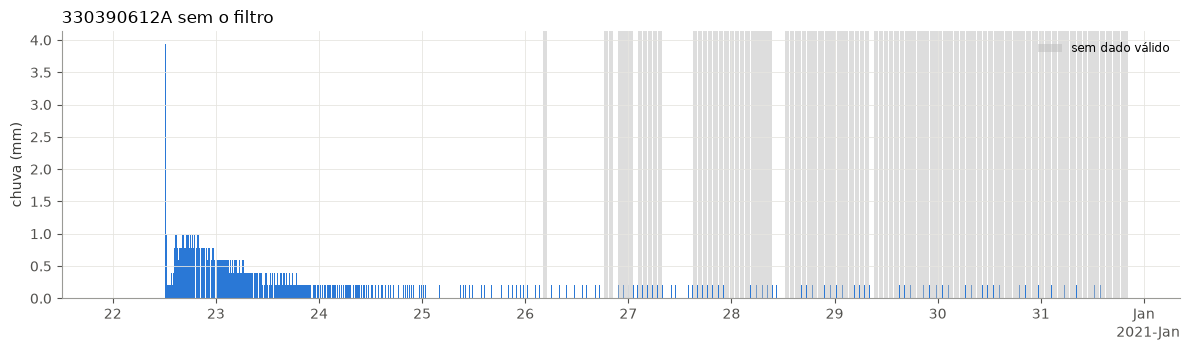

In [13]:
fig = figuras.serie_chuva(
    sem_filtro,                   # pluv_reg[cod] (falhas em cinza) ou uma série de chuva em qualquer resolução
    inicio='2020-12-22',          # recorte do período (None = tudo)
    fim='2021-01-01',
    titulo=f'{cod} sem o filtro',
)

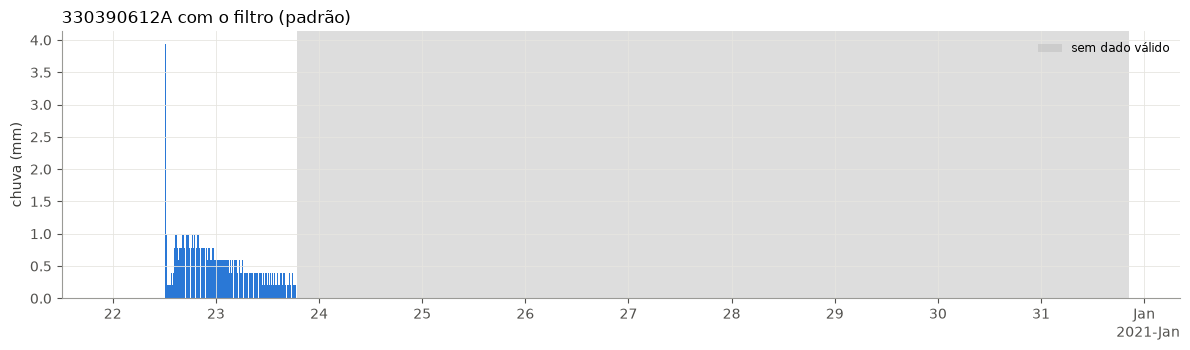

In [14]:
fig = figuras.serie_chuva(com_filtro, '2020-12-22', '2021-01-01', titulo=f'{cod} com o filtro (padrão)')

In [15]:
# Quanto o filtro retirou em cada estação
relatorio[['n_leituras_repetidas', 'mm_repetidos_descartados']].sort_values('mm_repetidos_descartados', ascending=False).head(8)

,n_leituras_repetidas,mm_repetidos_descartados
330390612A,764,152.8
330390609A,584,116.8
330390602G,174,34.8
330390605G,166,33.2
330390618A,0,0.0


### `figuras.status_pluv`

A situação de todas as estações de uma vez: uma linha por estação e uma coluna por período, do vermelho
(nenhum dado válido) ao verde (período completo); cinza = fora do período da estação.

- **Entrada:** `pluv_reg` (o dicionário inteiro).
- **Parâmetro:** `freq='MS'` (uma coluna por mês); `freq='D'` dá uma coluna por dia, boa para períodos curtos.

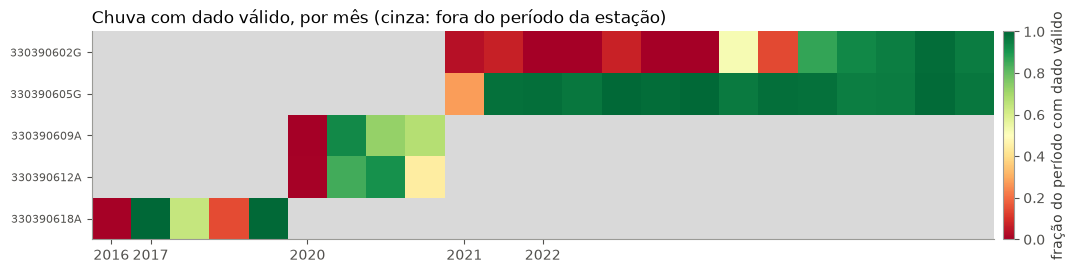

In [16]:
fig = figuras.status_pluv(
    pluv_reg,
    freq='MS',                    # tamanho de cada coluna: 'MS' = mês, 'D' = dia
    ax=None,                      # eixo do matplotlib, para desenhar numa figura sua (None = figura nova)
)

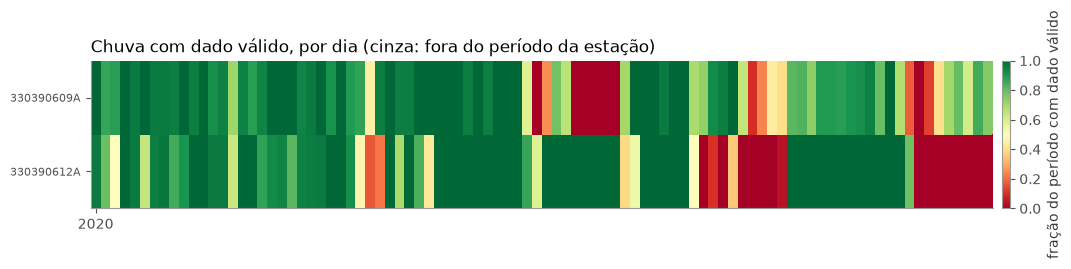

In [17]:
# Por dia, no fim de 2020 (só as estações com dado no período) - EXEMPLO DE FREQUENCIA DIÁRIA
trecho = {c: r.loc['2020-10-01':'2020-12-31'] for c, r in pluv_reg.items() if len(r.loc['2020-10-01':'2020-12-31']) > 1}
fig = figuras.status_pluv(trecho, freq='D')

### `figuras.serie_chuva` e `figuras.serie_chuva_interativo`

Chuva em barras ao longo do tempo. Com a tabela regular (`pluv_reg[cod]`), os trechos sem dado válido
aparecem em cinza; aceita também uma série em qualquer resolução (ex.: a chuva diária da etapa 5).
A versão `_interativo` tem as mesmas entradas, com zoom e valores ao passar o mouse.

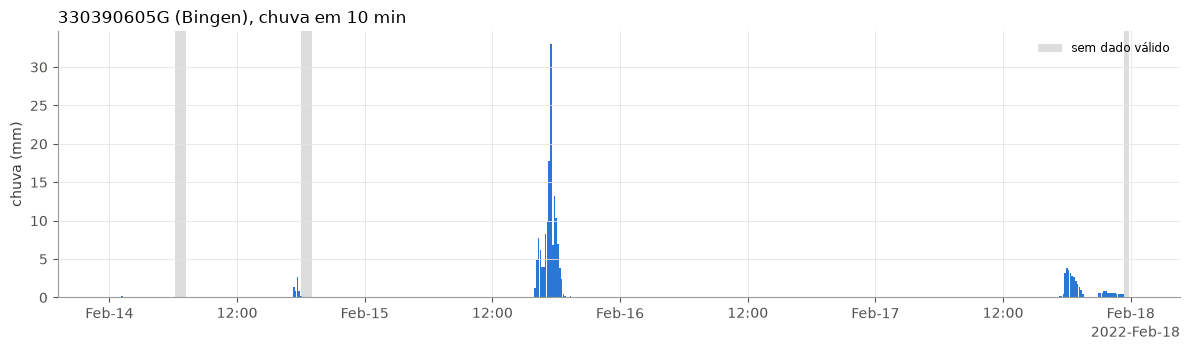

In [18]:
# O evento de 15/02/2022 na estação 330390605G (Bingen)
fig = figuras.serie_chuva(pluv_reg['330390605G'], '2022-02-14', '2022-02-17', titulo='330390605G (Bingen), chuva em 10 min')

In [19]:
fig_i = figuras.serie_chuva_interativo(
    pluv_reg['330390605G'],       # as mesmas entradas de serie_chuva
    inicio='2022-02-14',
    fim='2022-02-17',
    titulo='330390605G (Bingen)',
)

fig_i

### `chuva.acumulados` (janela móvel)

Somas em **janela móvel**: a cada 10 min, a chuva das últimas N horas. `acum_24h` às 15:00 de 15/02 é a
chuva de 15:00 de 14/02 até 15:00 de 15/02. Serve para máximos e limiares, que podem atravessar a
meia-noite. Para totais por hora redonda, dia civil ou mês (blocos fixos), use
`resolucao.reamostrar_chuva` (etapa 5).

- **Entrada:** `pluv_reg[cod]`. **Parâmetros:** `janelas`; `fracao_falha_max=0` (fração da janela, de 0 a
  1, que pode estar em falha; com 0, qualquer falha invalida a janela).

In [20]:
acum = chuva.acumulados(
    pluv_reg['330390605G'],
    janelas=('1h', '3h', '24h', '72h', '30D'),   # durações das janelas móveis (padrão: 1h a 30D)
    fracao_falha_max=0.0,         # fração da janela que pode estar em falha (0 = qualquer falha invalida)
)
# Os acumulados de 24 h ou mais aparecem como NaN aqui porque a estação teve falha em 14/02:
# toda janela que contém a falha é invalidada (use fracao_falha_max para tolerar).
acum.loc['2022-02-15 16:00':'2022-02-15 19:00':3]

,acum_1h,acum_3h,acum_24h,acum_72h,acum_30D
datahora,,,,,
2022-02-15 16:00:00,1.2,1.2,NaN,NaN,NaN
2022-02-15 16:30:00,20.2,20.2,NaN,NaN,NaN
2022-02-15 17:00:00,35.2,36.4,NaN,NaN,NaN
2022-02-15 17:30:00,77.0,97.2,NaN,NaN,NaN
2022-02-15 18:00:00,91.2,127.6,NaN,NaN,NaN
2022-02-15 18:30:00,43.6,140.8,NaN,NaN,NaN
2022-02-15 19:00:00,13.8,140.2,141.4,NaN,NaN


### `chuva.resumo_estacao`

O resumo da estação: funcionamento, maior acumulado em cada janela móvel (com a data), percentis da
chuva diária (50, 90, 95 e 99, sobre todos os dias válidos e só sobre os dias com 1 mm ou mais) e médias
mensais e anuais dos períodos completos (90 % ou mais de dado válido).

In [21]:
pd.Series(chuva.resumo_estacao(
    pluv_reg['330390605G'],       # uma estação (devolve dict) ou o dicionário inteiro (devolve tabela)
    janelas=('1h', '3h', '6h', '12h', '24h', '36h', '48h', '72h', '7D'),   # janelas dos máximos acumulados
    fracao_falha_max=0.0,         # fração de cada janela e de cada dia que pode estar em falha
    fracao_min_periodo=0.9,       # fração mínima de dados válidos para um mês (ou ano) entrar nas médias
    q=(50, 90, 95, 99),           # percentis da chuva diária
    limiar_chuvoso=1.0,           # mm a partir dos quais o dia conta como chuvoso (ETCCDI)
    inicio_dia=0,                 # hora em que o dia começa (0 = dia civil)
))

inicio                  2021-11-22 16:10:00
fim                     2022-12-31 20:50:00
total_dias                              405
funcionamento_%                       97.61
horas_em_falha                        182.3
n_falhas_longas                         122
maior_falha_h                          14.2
n_retornos_pos_falha                    122
n_leituras_altas                          1
leitura_max_mm                         33.0
data_leitura_max        2022-02-15 17:30:00
max_1h                                 91.2
data_max_1h             2022-02-15 18:00:00
max_3h                                141.4
data_max_3h             2022-02-15 18:50:00
max_6h                                165.0
data_max_6h             2022-03-20 20:00:00
max_12h                               272.8
data_max_12h            2022-03-21 02:00:00
max_24h                               327.4
data_max_24h            2022-03-21 12:40:00
max_36h                               327.8
data_max_36h            2022-03-

In [22]:
# Várias estações de uma vez: passe o dicionário e receba uma tabela, uma linha por estação
resumo = chuva.resumo_estacao(pluv_reg)
resumo[['funcionamento_%', 'max_1h', 'max_24h', 'p50_dia_chuvoso', 'p90_dia_chuvoso', 'p95_dia_chuvoso',
        'p99_dia_chuvoso', 'p95_dia', 'media_anual', 'n_anos_completos']].head(10)

,funcionamento_%,max_1h,max_24h,p50_dia_chuvoso,p90_dia_chuvoso,p95_dia_chuvoso,p99_dia_chuvoso,p95_dia,media_anual,n_anos_completos
330390602G,41.82,110.4,154.6,9.3,48.0,87.4,129.5,44.5,NaN,0
330390605G,97.61,91.2,327.4,12.2,47.7,69.7,164.5,33.4,2980.8,1
330390609A,77.67,2.36,5.2,2.2,2.9,3.0,3.2,2.2,NaN,0
330390612A,73.34,17.52,90.75,6.2,8.6,56.4,56.6,54.4,NaN,0
330390618A,69.53,63.83,103.26,10.1,44.5,73.6,87.1,44.9,NaN,0


## 3. Umidade do solo (PCDs Geo)

### `leitura.umidade_por_estacao` e `figuras.serie_umidade_interativo`: identificar a acomodação

Depois de instalada, a sonda passa semanas ou meses se acomodando: as camadas fundas descem sem relação
com a chuva. Esse período é **informado por você**. `umidade_por_estacao` separa a umidade bruta de cada
PCD Geo (`umid_raw`), e `serie_umidade_interativo` é a ferramenta para identificar a acomodação: dê zoom,
passe o mouse no ponto em que as curvas estabilizam e leia a data. A faixa amarela (`acomodacao=`) mostra
um período candidato, para conferir a escolha.

- **Entrada:** `umid_raw[cod]`; a chuva (opcional) vai no painel de baixo.
- **Parâmetros:** `freq='1h'` (resolução do desenho; '3h' deixa a figura mais leve), `acomodacao`, `inicio`, `fim`.

In [23]:
umid_raw = leitura.umidade_por_estacao(dados_geo)        # {código: tabela n1..n6}; a 605G foi instalada em nov/2021
fig_u = figuras.serie_umidade_interativo(
    umid_raw['330390605G'],                  # umidade n1..n6 (%) de uma estação, em qualquer resolução
    pluv=pluv_reg['330390605G']['chuva_mm'], # chuva (mm) no painel de baixo (None = sem chuva)
    inicio=None,                             # recorte do período (None = tudo)
    fim=None,
    niveis=None,                             # lista de níveis a mostrar, ex.: ['n1', 'n2'] (None = todos)
    freq='3h',                               # resolução do desenho (padrão '1h'; None = como veio)
    acomodacao=('2021-11-01', '2022-07-31'), # período a sombrear em amarelo (candidato à acomodação)
    titulo='330390605G bruta',
)
fig_u

### `umidade.limpar_umidade`

Diagnostica e limpa a umidade de **uma estação**, direto da tabela lida. As regras de **falha** são
falhas inequívocas do equipamento e viram NaN; as **suspeitas** podem ser reais e, no padrão, só ficam
sinalizadas para você decidir.

| Regra | Classe | O que pega | Parâmetro |
|---|---|---|---|
| zero exato | falha | código de falha do equipamento | |
| acima de 60 % | falha | fora da faixa física | `maximo=60.0` |
| valor congelado por 24 h ou mais | falha | datalogger repetindo a última leitura | `congelado_min='24h'` |
| queda simultânea (3 ou mais níveis) | falha | falha elétrica (critério empírico) | `limiar_queda=1.5` |
| queda isolada que volta | suspeita | leitura espúria para baixo | `limiar_queda=1.5` |
| pico sem chuva | suspeita | leitura espúria para cima | `limiar_pico=3.0` |
| acomodação pós-instalação | sempre aplicada | o período que você informou | `acomodacao=(inicio, fim)` |

**Base das regras.** As regras de faixa, valor congelado, queda isolada (pico para baixo), pico sem chuva
e degraus são **adaptações simplificadas** das categorias do controle de qualidade automático da
International Soil Moisture Network (ISMN), descritas por Dorigo et al. (2013). O artigo fornece as
categorias; os algoritmos usados aqui são mais simples que os do artigo (medianas antes e depois, em vez
de derivadas da série), e os limiares foram ajustados empiricamente aos dados de Petrópolis. A queda
simultânea e a acomodação não constam do artigo: são critérios empíricos. Detalhes em `docs/regras.md`.

> Dorigo, W. A. et al. (2013). Global automated quality control of in situ soil moisture data from the
> International Soil Moisture Network. *Vadose Zone Journal*, 12(3). https://doi.org/10.2136/vzj2012.0097

- **Entrada:** `dados` (lidos sem filtrar sensores) e o código da estação.
- **Modo** (`excluir`): `'falhas'` (padrão) apaga só as falhas; `'todas'` apaga também as suspeitas;
  `'nenhuma'` só sinaliza. Degraus e descontinuidades são sempre só listados.
- **Chuva:** a regra do pico precisa saber se choveu. A função busca sozinha a chuva da própria estação
  (sensor 10, no mesmo arquivo do PED), soma por hora e guarda em `pluv_h`; dá erro se ela não estiver
  nos dados. Quem já tem a chuva horária tratada pode passá-la em `pluv_h=`.
- **Saída:** `umid_clean[cod]`; a série a usar é `umid_clean[cod].operacional` (limpa e sem a acomodação).
  Para hora ou dia, use `resolucao.reamostrar_umidade` (etapa 5).

In [24]:
umid_clean = {}
umid_clean['330390605G'] = umidade.limpar_umidade(
    dados_geo,                               # tabela de ler_dados com a umidade e a chuva da estação
    '330390605G',                            # código completo da estação
    acomodacao=('2021-11-01', '2022-07-31'), # período pós-instalação, sempre excluído (escolhido na figura)
    maximo=60.0,                             # % acima do qual a leitura é falha (fora da faixa)
    congelado_min='24h',                     # duração mínima do mesmo valor para ser "congelado"
    limiar_queda=1.5,                        # p.p. da queda que volta (isolada ou simultânea)
    limiar_pico=3.0,                         # p.p. do pico sem chuva
    excluir='falhas',                        # o que vira NaN: 'falhas', 'todas' (também as suspeitas) ou 'nenhuma'
    pluv_h=None,                             # chuva horária pronta; None = usa o sensor 10 da própria estação
)
pd.Series(umid_clean['330390605G'].resumo)

leituras              190814.0
espurias                 170.0
espurias_%                 0.1
excluidas                 31.0
excluidas_%                0.0
so_sinalizadas           139.0
em_acomodacao         115112.0
n_zero                     0.0
n_faixa                    0.0
n_congelado               25.0
n_queda_simultanea         6.0
n_queda_isolada          139.0
n_pico                     0.0
n_exclusao_manual          0.0
n_degraus                  0.0
n_descontinuidades         0.0
dtype: float64

### Onde cada regra marcou: `umid_clean[cod].mascaras`

As regras marcam leitura por leitura. Cada máscara em `mascaras` tem o formato da série (datahora ×
n1..n6), com `True` onde a regra marcou: `zero`, `faixa`, `congelado`, `queda_simultanea`,
`queda_isolada`, `pico` e `exclusao_manual`. As regras que viraram NaN estão em `excluidas`; as outras
só sinalizam. Contar as marcas por dia mostra onde estão as suspeitas, para avaliar na figura e decidir
o que excluir à mão na etapa 4.

In [25]:
print('viraram NaN:', umid_clean['330390605G'].excluidas)
m = umid_clean['330390605G'].mascaras['queda_isolada']      # suspeita: só sinalizada no padrão
por_dia = m.resample('1D').sum()                            # leituras marcadas por dia, em cada nível
por_dia[por_dia.sum(axis=1) > 0]

viraram NaN: ('zero', 'faixa', 'congelado', 'queda_simultanea', 'exclusao_manual')


,n1,n2,n3,n4,n5,n6
datahora,,,,,,
2022-03-11,8,0,0,0,0,0
2022-03-12,18,0,0,0,0,0
2022-03-19,7,0,0,0,0,0
2022-03-20,25,3,6,0,0,0
2022-03-21,2,0,0,0,0,0
2022-08-11,0,5,0,0,0,0
2022-08-19,0,10,0,0,0,0
2022-08-29,0,0,2,0,0,0
2022-11-02,0,37,0,0,0,0


In [26]:
# Degraus (mudanças de patamar): só listados, para você avaliar
umid_clean['330390605G'].degraus.head()

,datahora,nivel,salto,chuva12h,motivo


### `figuras.status_umid`: várias estações

A situação diária de várias PCDs Geo: operando, dia com quedas simultâneas, acomodação, falha ou sem
dados. **Entrada:** `umid_clean` (o dicionário inteiro), `inicio` e `fim`.

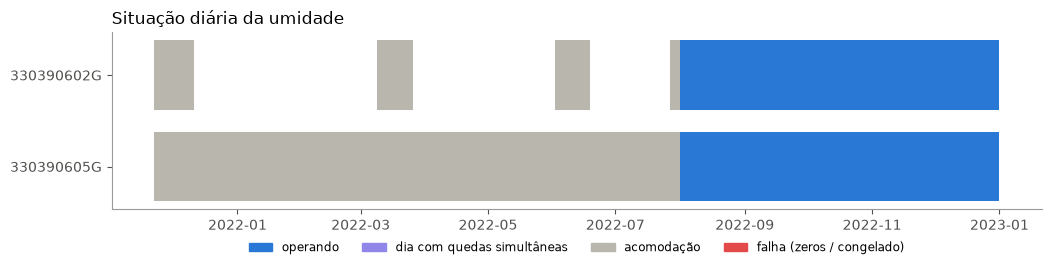

In [27]:
# Limpa a outra PCD Geo do recorte do mesmo jeito (acomodação identificada como na figura da 605G)
dados_02g, _, _ = leitura.ler_dados(DADOS / 'PED_Cemaden_330390602G.csv.gz')
umid_clean['330390602G'] = umidade.limpar_umidade(dados_02g, '330390602G', acomodacao=('2021-11-01', '2022-07-31'))

fig = figuras.status_umid(
    umid_clean,
    inicio='2021-11-01',          # período da figura
    fim='2022-12-31',
    ax=None,                      # eixo do matplotlib (None = figura nova)
)

## 4. Exclusão manual: `exclusao.excluir_periodos`

A mesma função para a chuva e para a umidade: retira o que você identificou como espúrio e que as regras
não pegaram (ou só sinalizaram). Devolve um objeto novo, do mesmo tipo, e a exclusão fica registrada.
A lista `exclusoes` fica no notebook, como registro da decisão.

- **Entrada:** `pluv_reg[cod]` ou `umid_clean[cod]`.
- **`exclusoes`:** uma lista; cada item é um instante (`'2023-09-18 17:00'`), um intervalo
  (`(inicio, fim)`) ou, só na umidade, um intervalo com os níveis (`(inicio, fim, ['n1'])`). Sem a lista de
  níveis, a exclusão vale para **todas as profundidades**.

Na umidade, avalie as suspeitas marcadas em `mascaras` (por exemplo, com `serie_umidade_interativo` na série
limpa) e exclua as que julgar espúrias. Aqui, para exemplificar, excluímos a queda isolada de 02/11/2022,
que só aparece em n2.

In [28]:
antes = umid_clean['330390605G']
umid_clean['330390605G'] = exclusao.excluir_periodos(antes, [('2022-11-02 00:50', '2022-11-02 16:30', ['n2'])])
t = slice('2022-11-02 00:50', '2022-11-02 16:30')
depois = umid_clean['330390605G']
pd.DataFrame({'leituras válidas antes': antes.limpo.loc[t].count(),
              'leituras válidas depois': depois.limpo.loc[t].count()})        # só n2 muda

,leituras válidas antes,leituras válidas depois
n1,95,95
n2,95,0
n3,95,95
n4,95,95
n5,95,95
n6,95,95


Na chuva funciona igual, e a exclusão fica marcada na coluna `exclusao_manual`. Aqui excluímos uma
leitura qualquer, só para mostrar o funcionamento (ela não é espúria).

In [29]:
exemplo = exclusao.excluir_periodos(pluv_reg['330390605G'], ['2022-01-16 20:20'])     # um instante
exemplo.loc['2022-01-16 20:10':'2022-01-16 20:30', ['valor_original', 'chuva_mm', 'valido', 'exclusao_manual']]

,valor_original,chuva_mm,valido,exclusao_manual
datahora,,,,
2022-01-16 20:10:00,10.4,10.4,True,False
2022-01-16 20:20:00,17.0,NaN,False,True
2022-01-16 20:30:00,2.4,2.4,True,False


## 5. Ajuste da resolução temporal

### `resolucao.reamostrar_chuva`

Soma a chuva em **blocos fixos** do calendário (hora, dia, mês), ao contrário de `chuva.acumulados`, que
usa janela móvel. Cada período é rotulado pelo seu **início** e reúne a chuva que caiu dentro dele. Como
cada registro do Cemaden traz a chuva dos 10 min que terminam no seu horário, o dia 15/02 soma os
registros de 15/02 00:10 a 16/02 00:00 (o registro de 00:00 é chuva do dia anterior).

- **Entrada:** `pluv_reg[cod]`.
- **Parâmetros:** `freq` ('1h', '1D', 'MS'...); `fracao_falha_max=0` (fração do período, de 0 a 1, que
  pode estar em falha; com 0, qualquer falha deixa o período NaN); `inicio_dia=0` (hora em que o dia começa).
- **Saída:** `chuva_mm`, `n_validos`, `n_esperados`, `incompleto` (faltou algum intervalo, mesmo dentro
  da tolerância) e `valido`.

In [30]:
horaria = resolucao.reamostrar_chuva(
    pluv_reg['330390605G'],
    freq='1h',                    # resolução de saída: '1h', '3h', '1D', 'MS' (mês), 'YS' (ano)...
    fracao_falha_max=0.0,         # fração do período que pode estar em falha (0 = qualquer falha dá NaN)
    inicio_dia=0,                 # hora em que o dia começa (vale para '1D' e maiores)
)
horaria.loc['2022-02-15 15:00':'2022-02-15 21:00']

,chuva_mm,n_validos,n_esperados,incompleto,valido
datahora,,,,,
2022-02-15 15:00:00,1.2,6,6,False,True
2022-02-15 16:00:00,35.2,6,6,False,True
2022-02-15 17:00:00,91.2,6,6,False,True
2022-02-15 18:00:00,13.8,6,6,False,True
2022-02-15 19:00:00,0.2,6,6,False,True
2022-02-15 20:00:00,0.0,6,6,False,True
2022-02-15 21:00:00,0.0,6,6,False,True


In [31]:
# Diária, para todas as estações (rs = resample); e mensal, tolerando 2 % do mês em falha
pluv_rs = {cod: resolucao.reamostrar_chuva(reg, '1D') for cod, reg in pluv_reg.items()}
mensal = resolucao.reamostrar_chuva(pluv_reg['330390605G'], 'MS', fracao_falha_max=0.02)
mensal.loc['2022'].round(1)

,chuva_mm,n_validos,n_esperados,incompleto,valido
datahora,,,,,
2022-01-01,430.4,4393,4464,True,True
2022-02-01,NaN,3891,4032,True,False
2022-03-01,405.0,4434,4464,True,True
2022-04-01,190.6,4254,4320,True,True
2022-05-01,25.4,4440,4464,True,True
2022-06-01,NaN,4137,4320,True,False
2022-07-01,31.8,4379,4464,True,True
2022-08-01,NaN,4365,4464,True,False
2022-09-01,NaN,4116,4320,True,False


In [32]:
# O dia que começa às 9 h (rotulado 09:00) em vez da meia-noite
pd.DataFrame({'dia civil': pluv_rs['330390605G'].loc['2022-02-14':'2022-02-17', 'chuva_mm'].values,
              'dia das 9 h': resolucao.reamostrar_chuva(pluv_reg['330390605G'], '1D', inicio_dia=9)
                                      .loc['2022-02-14':'2022-02-17', 'chuva_mm'].values},
             index=pd.date_range('2022-02-14', '2022-02-17').date)

,dia civil,dia das 9 h
2022-02-14,NaN,NaN
2022-02-15,141.6,141.6
2022-02-16,0.0,0.0
2022-02-17,NaN,NaN


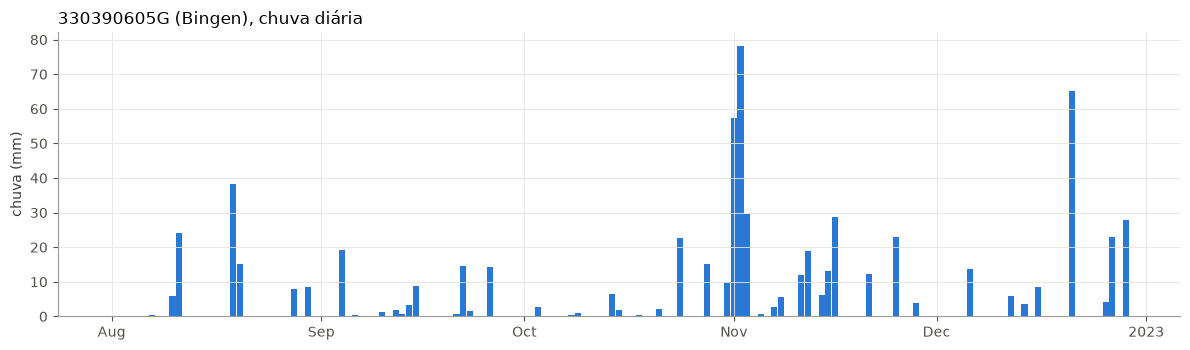

In [33]:
# A mesma função de figura aceita qualquer resolução: a chuva diária do 2º semestre de 2022
fig = figuras.serie_chuva(pluv_rs['330390605G']['chuva_mm'], '2022-08-01', '2022-12-31', titulo='330390605G (Bingen), chuva diária')

### `resolucao.reamostrar_umidade`

A umidade é uma grandeza de estado: agrega-se pela **média** (ou mediana) das leituras de cada bloco fixo,
com um número mínimo de leituras para o período valer.

- **Entrada:** `umid_clean[cod].operacional` (aceita a própria saída: horária → diária).
- **Parâmetros:** `freq`; `agregacao='media'` ou `'mediana'`; `min_leituras=1`; `inicio_dia=0`.
- **Saída:** `umid_rs[cod]`, as colunas n1..n6 e `incompleto` (alguma hora do período ficou sem leitura).

In [34]:
umid_rs = {}
umid_rs['330390605G'] = resolucao.reamostrar_umidade(
    umid_clean['330390605G'].operacional,   # a série limpa a usar
    freq='1h',                    # resolução de saída
    agregacao='media',            # 'media' ou 'mediana'
    min_leituras=1,               # nº mínimo de leituras no período para ele valer (abaixo, NaN)
    inicio_dia=0,                 # hora em que o dia começa
)
diaria_u = resolucao.reamostrar_umidade(umid_rs['330390605G'], '1D', agregacao='mediana', min_leituras=18)  # dia com 18 h ou mais
diaria_u.loc['2022-11-01':'2022-11-06'].round(2)

,n1,n2,n3,n4,n5,n6,incompleto
datahora,,,,,,,
2022-11-01,32.48,26.42,25.30,30.34,29.05,30.11,False
2022-11-02,34.98,NaN,27.36,30.41,29.04,30.10,False
2022-11-03,34.29,30.86,26.94,32.47,30.78,30.60,False
2022-11-04,33.85,30.25,26.65,32.11,30.66,31.71,False
2022-11-05,33.24,30.01,26.48,31.91,30.52,31.63,False
2022-11-06,32.38,29.37,26.34,31.78,30.41,31.52,False


### `figuras.serie_umidade`

Umidade por tempo, uma linha por profundidade, com a chuva embaixo se for dada. Aceita a umidade em
qualquer resolução; `freq` agrega o desenho quando a série é mais fina, e `acomodacao` sombreia um período.

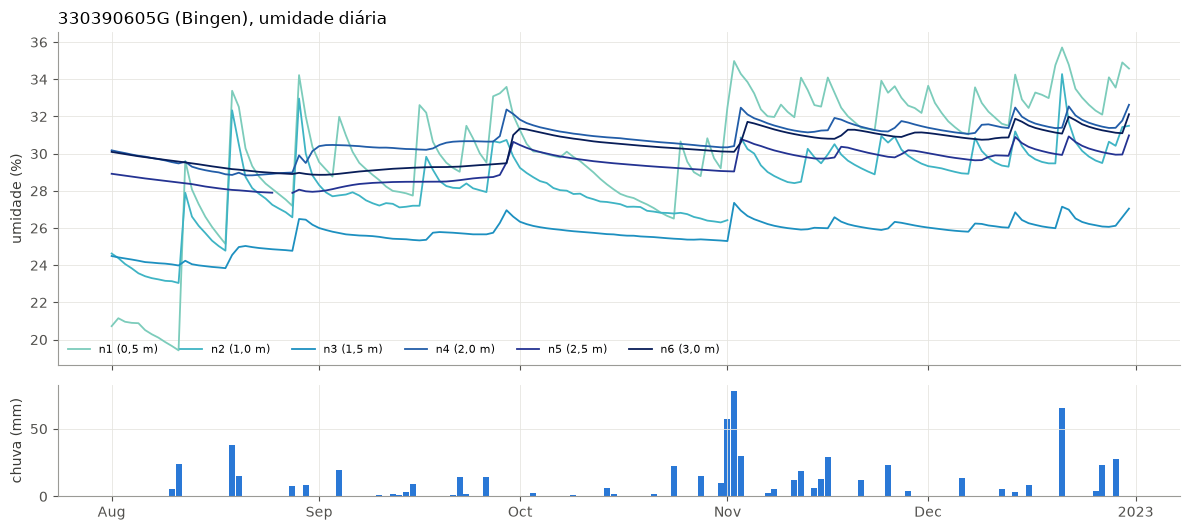

In [35]:
fig = figuras.serie_umidade(
    diaria_u,
    pluv=pluv_rs['330390605G']['chuva_mm'],
    inicio='2022-08-01',
    fim='2022-12-31',
    niveis=None,
    freq='1D',
    acomodacao=None,
    titulo='330390605G (Bingen), umidade diária',
)                                 # os mesmos parâmetros de serie_umidade_interativo

## 6. Exportar

As saídas vão para `saida_exemplo/`, nunca para a pasta dos originais. O padrão é o CSV internacional
(vírgula e ponto decimal); para abrir direto no Excel brasileiro, use `sep=';'` e `decimal=','`.
Figuras do matplotlib se gravam com `figuras.salvar`; as interativas, com `fig.write_html`.

In [36]:
pluv_reg['330390605G'].join(acum).to_csv(SAIDA / '05G_chuva_10min.csv')
horaria.to_csv(SAIDA / '05G_chuva_horaria.csv')
pluv_rs['330390605G'].to_csv(SAIDA / '05G_chuva_diaria.csv')
umid_rs['330390605G'].to_csv(SAIDA / '05G_umidade_horaria.csv')
relatorio.to_csv(SAIDA / 'relatorio_falhas.csv', sep=';', decimal=',')      # formato do Excel brasileiro
figuras.salvar(figuras.status_pluv(pluv_reg), SAIDA / 'status_pluv.png',
               dpi=110)           # resolução da imagem
sorted(p.name for p in SAIDA.iterdir())

['05G_chuva_10min.csv',
 '05G_chuva_diaria.csv',
 '05G_chuva_horaria.csv',
 '05G_umidade_horaria.csv',
 'relatorio_falhas.csv',
 'status_pluv.png']